# Importanto as bibliotecas


In [1]:
!pip install scikit-learn==1.5.0

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 27.0 MB/s  0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for scikit-learn: filename=scikit_learn-1.5.0-cp313-cp313-linux_x86_64.whl size=12146853 sha256=6ba0465b2c47ed0d1c60d8b0a1440b2eef901d45656a57afbc20def1d5bb1851
  Stored in directory: /root/.cache/pip/wheels/93/ca/a2/91447811bdd24ef22514608de2a4c31de2e3852b876d69aa00
Successfully built scikit-learn
  Attempting uninstall: scikit-learn
    Found existing installation: scikit-learn 1.6.1
    Uninstalling scikit-learn-1.6.1:
      Successfully uninstalled scikit-learn-1.6.1
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
umap-learn 0.5.12 requires scikit-learn>=1.6, but you have scikit-learn 1.5.0 w

In [2]:
import pandas as pd
import numpy as np
from pandas import DataFrame
import seaborn as sns
from google.colab import drive
import plotly.express as px
import plotly.graph_objects as go
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import classification_report
from sklearn.model_selection import train_test_split
from sklearn.model_selection import KFold
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, export_graphviz
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
import graphviz
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.datasets import load_iris
#from googletrans import Translator
import joblib
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import LabelEncoder
from google.colab import files

# Dicionário de dados




1.   Sex = gênero: male (masculino) ou female (feminino)
2.   Age = idade
3.   Pclass - classe do navio (1, 2 ou 3)
4.   Embarked = Porto de embarque (C = Cherbourg, Q = Queenstown, S = Southampton)
5.   Fare = Tarifa paga pelo passageiro
6.   Survived - Se o passageiro sobreviveu (1 = sim, 0 = não)










# Carregando os dados

In [4]:
drive.mount('/content/gdrive/')

Mounted at /content/gdrive/


In [5]:
dados = pd.read_csv("/content/gdrive/My Drive/titanic/train.csv")

In [6]:
dados

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


In [7]:

dados.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


# Análise de Dados

# Porcentagem de sobreviventes

In [8]:
fig = px.pie(dados, names='Survived', title='Porcentagem de Sobreviventes')
fig.show()

# Porcentagem de Gênero

In [9]:

# Porcentagem de Gênero
fig = px.pie(dados, names='Sex', title='Porcentagem de Gênero')
fig.show()


# Distribuição de Idade

In [10]:

fig = px.histogram(dados, x="Age", nbins=20, title="Distribuição de Idade")
fig.show()


# Distribuição de Tarifa

In [11]:


fig = px.histogram(dados, x="Fare", nbins=20, title="Distribuição de Tarifa")
fig.show()


# Gênero por Sobrevivência

In [12]:
df_grouped = dados.groupby(['Sex', 'Survived'])['PassengerId'].count().reset_index(name='Count')
df_total = dados.groupby(['Sex'])['PassengerId'].count().reset_index(name='Total')
df_percentual = pd.merge(df_grouped, df_total, on='Sex', how='left')
df_percentual['Percentual'] = (df_percentual['Count'] / df_percentual['Total']) * 100

fig = px.bar(df_percentual, x="Sex", y="Percentual", color="Survived",
             title='Percentual de Sexo por Sobrevivência',
             labels={'Sex': 'Sexo', 'Percentual': 'Percentual', 'Survived': 'Sobreviveu'})
fig.show()


In [13]:

from scipy.stats import chi2_contingency

# Criando a tabela de contingência
contingency_table = pd.crosstab(dados['Sex'], dados['Survived'])

# Realizando o teste de qui-quadrado
chi2, p, dof, expected = chi2_contingency(contingency_table)

# Imprimindo os resultados
print(f"Valor do qui-quadrado: {chi2}")
print(f"Valor-p: {p}")
print(f"Graus de liberdade: {dof}")
print("Tabela de frequências esperadas:")
print(expected)

# Interpretando o resultado
alpha = 0.05  # Nível de significância
if p < alpha:
    print("Rejeitamos a hipótese nula. Há uma associação significativa entre Sexo e Sobrevivência.")
else:
    print("Aceitamos a hipótese nula. Não há evidências suficientes para sugerir uma associação entre Sexo e Sobrevivência.")


Valor do qui-quadrado: 260.71702016732104
Valor-p: 1.1973570627755645e-58
Graus de liberdade: 1
Tabela de frequências esperadas:
[[193.47474747 120.52525253]
 [355.52525253 221.47474747]]
Rejeitamos a hipótese nula. Há uma associação significativa entre Sexo e Sobrevivência.


# Classe Social por Sobrevivência

In [14]:

df_grouped = dados.groupby(['Pclass', 'Survived'])['PassengerId'].count().reset_index(name='Count')
df_total = dados.groupby(['Pclass'])['PassengerId'].count().reset_index(name='Total')
df_percentual = pd.merge(df_grouped, df_total, on='Pclass', how='left')
df_percentual['Percentual'] = (df_percentual['Count'] / df_percentual['Total']) * 100

fig = px.bar(df_percentual, x="Pclass", y="Percentual", color="Survived",
             title='Percentual de Pclass por Sobrevivência',
             labels={'Pclass': 'Classe', 'Percentual': 'Percentual', 'Survived': 'Sobreviveu'})
fig.show()

In [15]:
# Criando a tabela de contingência
contingency_table = pd.crosstab(dados['Pclass'], dados['Survived'])

# Realizando o teste de qui-quadrado
from scipy.stats import chi2_contingency
chi2, p, dof, expected = chi2_contingency(contingency_table)

# Imprimindo os resultados
print(f"Valor do qui-quadrado: {chi2}")
print(f"Valor-p: {p}")
print(f"Graus de liberdade: {dof}")
print("Tabela de frequências esperadas:")
print(expected)

# Interpretando o resultado
alpha = 0.05  # Nível de significância
if p < alpha:
    print("Rejeitamos a hipótese nula. Há uma associação significativa entre Classe e Sobrevivência.")
else:
    print("Aceitamos a hipótese nula. Não há evidências suficientes para sugerir uma associação entre Classe e Sobrevivência.")


Valor do qui-quadrado: 102.88898875696056
Valor-p: 4.549251711298793e-23
Graus de liberdade: 2
Tabela de frequências esperadas:
[[133.09090909  82.90909091]
 [113.37373737  70.62626263]
 [302.53535354 188.46464646]]
Rejeitamos a hipótese nula. Há uma associação significativa entre Classe e Sobrevivência.


# Porto de Embarque por Sobrevivência

In [16]:

df_grouped = dados.groupby(['Embarked', 'Survived'])['PassengerId'].count().reset_index(name='Count')
df_total = dados.groupby(['Embarked'])['PassengerId'].count().reset_index(name='Total')
df_percentual = pd.merge(df_grouped, df_total, on='Embarked', how='left')
df_percentual['Percentual'] = (df_percentual['Count'] / df_percentual['Total']) * 100

fig = px.bar(df_percentual, x="Embarked", y="Percentual", color="Survived",
             title='Percentual de Embarked por Sobrevivência',
             labels={'Embarked': 'Porto de embarque', 'Percentual': 'Percentual', 'Survived': 'Sobreviveu'})
fig.show()

In [17]:
from scipy.stats import chi2_contingency

# Criando a tabela de contingência
contingency_table = pd.crosstab(dados['Embarked'], dados['Survived'])

# Realizando o teste de qui-quadrado
chi2, p, dof, expected = chi2_contingency(contingency_table)

# Imprimindo os resultados
print(f"Valor do qui-quadrado: {chi2}")
print(f"Valor-p: {p}")
print(f"Graus de liberdade: {dof}")
print("Tabela de frequências esperadas:")
print(expected)

# Interpretando o resultado
alpha = 0.05  # Nível de significância
if p < alpha:
    print("Rejeitamos a hipótese nula. Há uma associação significativa entre Porto de Embarque e Sobrevivência.")
else:
    print("Aceitamos a hipótese nula. Não há evidências suficientes para sugerir uma associação entre Porto de Embarque e Sobrevivência.")


Valor do qui-quadrado: 26.48914983923762
Valor-p: 1.769922284120912e-06
Graus de liberdade: 2
Tabela de frequências esperadas:
[[103.7480315  64.2519685]
 [ 47.5511811  29.4488189]
 [397.7007874 246.2992126]]
Rejeitamos a hipótese nula. Há uma associação significativa entre Porto de Embarque e Sobrevivência.


# Classe Social por Porto de Embarque

In [18]:
# Agrupando os dados por Pclass e Embarked e contando os passageiros
df_grouped = dados.groupby(['Pclass', 'Embarked'])['PassengerId'].count().reset_index(name='Count')

# Criando o gráfico de barras
fig = px.bar(df_grouped, x="Pclass", y="Count", color="Embarked",
             title='Contagem de Passageiros por Classe e Porto de Embarque',
             labels={'Pclass': 'Classe', 'Count': 'Contagem de Passageiros', 'Embarked': 'Porto de Embarque'})

# Exibindo o gráfico
fig.show()


In [19]:
# Agrupando os dados por Embarked e Pclass e contando os passageiros
df_grouped = dados.groupby(['Embarked', 'Pclass'])['PassengerId'].count().reset_index(name='Count')

# Calculando o total de passageiros por Embarked
df_total = dados.groupby(['Embarked'])['PassengerId'].count().reset_index(name='Total')

# Unindo os DataFrames para calcular o percentual
df_percentual = pd.merge(df_grouped, df_total, on='Embarked', how='left')
df_percentual['Percentual'] = (df_percentual['Count'] / df_percentual['Total']) * 100

# Criando o gráfico de barras
fig = px.bar(df_percentual, x="Embarked", y="Percentual", color="Pclass",
             title='Percentual de Pclass por Embarked',
             labels={'Embarked': 'Porto de Embarque', 'Percentual': 'Percentual', 'Pclass': 'Classe'})

# Exibindo o gráfico
fig.show()


# Idade por Sobrevivência

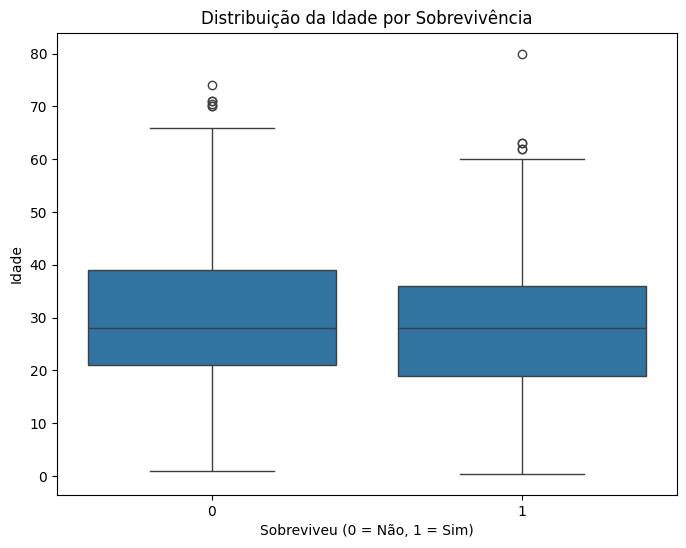

In [20]:
# Boxplot de Age por Survived
plt.figure(figsize=(8, 6))
sns.boxplot(x='Survived', y='Age', data=dados)
plt.title('Distribuição da Idade por Sobrevivência')
plt.xlabel('Sobreviveu (0 = Não, 1 = Sim)')
plt.ylabel('Idade')
plt.show()


# Tarifa Paga por Sobrevivência

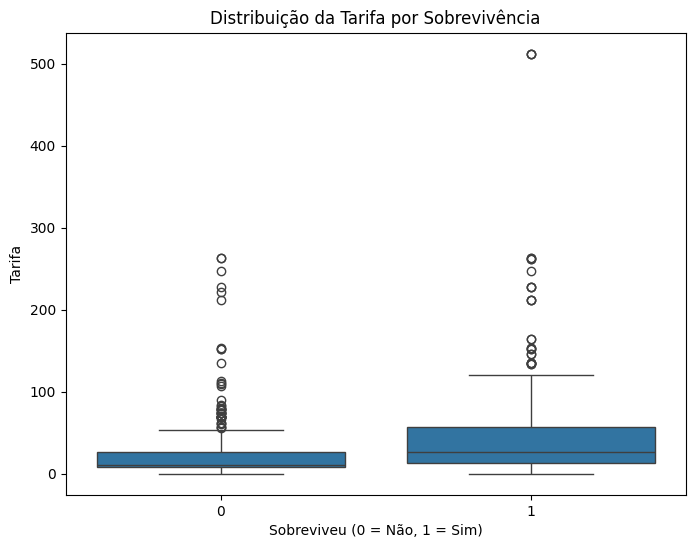

In [21]:
# Boxplot de Age por Survived
plt.figure(figsize=(8, 6))
sns.boxplot(x='Survived', y='Fare', data=dados)
plt.title('Distribuição da Tarifa por Sobrevivência')
plt.xlabel('Sobreviveu (0 = Não, 1 = Sim)')
plt.ylabel('Tarifa')
plt.show()

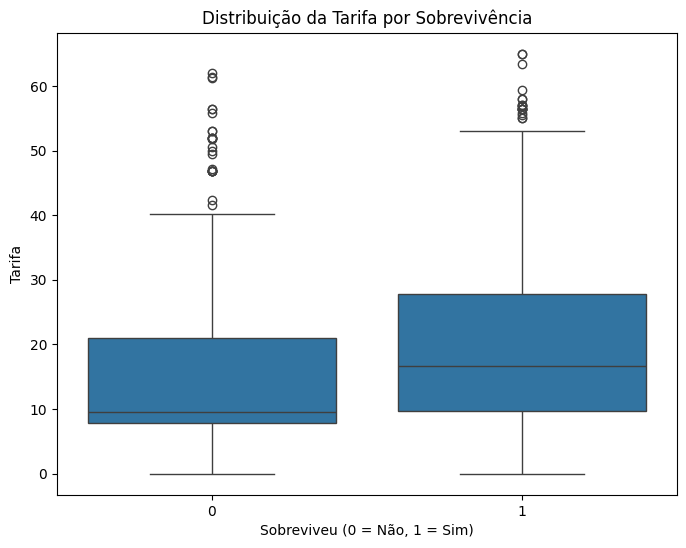

In [22]:
# Calculando os limites para outliers
Q1 = dados['Fare'].quantile(0.25)
Q3 = dados['Fare'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Removendo os outliers
dados_sem_outliers = dados[(dados['Fare'] >= lower_bound) & (dados['Fare'] <= upper_bound)]

# Boxplot de Age por Survived
plt.figure(figsize=(8, 6))
sns.boxplot(x='Survived', y='Fare', data=dados_sem_outliers)
plt.title('Distribuição da Tarifa por Sobrevivência')
plt.xlabel('Sobreviveu (0 = Não, 1 = Sim)')
plt.ylabel('Tarifa')
plt.show()


# Machine Learning

In [23]:

data_modelo = dados[[ 'Survived', 'Pclass', 'Sex', 'Age', 'Fare', 'Embarked']]

categorical_columns = ['Sex', 'Embarked']
numerical_columns = ['Pclass', 'Age', 'Fare']


In [24]:
le = LabelEncoder()

# Transformando e salvando os encoders
data_modelo['Sex'] = le.fit_transform(data_modelo['Sex'])
joblib.dump(le, 'label_encoder_Sex.pkl')
files.download(f'label_encoder_Sex.pkl')


data_modelo['Embarked'] = le.fit_transform(data_modelo['Embarked'])
joblib.dump(le, 'label_encoder_Embarked.pkl')
files.download(f'label_encoder_Embarked.pkl')



/tmp/ipykernel_4131/397485705.py:4: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

/tmp/ipykernel_4131/397485705.py:9: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [25]:
data_modelo

,Survived,Pclass,Sex,Age,Fare,Embarked
0,0,3,1,22.0,7.2500,2
1,1,1,0,38.0,71.2833,0
2,1,3,0,26.0,7.9250,2
3,1,1,0,35.0,53.1000,2
4,0,3,1,35.0,8.0500,2
...,...,...,...,...,...,...
886,0,2,1,27.0,13.0000,2
887,1,1,0,19.0,30.0000,2
888,0,3,0,NaN,23.4500,2
889,1,1,1,26.0,30.0000,0


In [26]:
from sklearn.preprocessing import LabelEncoder
import joblib
from google.colab import files

In [27]:
categorical_columns_for_transformer = ['Sex', 'Embarked']


In [28]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_columns),
        ('cat', 'passthrough', categorical_columns_for_transformer)
    ]
)

pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', HistGradientBoostingClassifier())
])

# DOWNLOAD

In [29]:


X = data_modelo[numerical_columns + categorical_columns]
y = data_modelo['Survived']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

pipeline.fit(X_train , y_train)

# Salvar o pipeline inteiro
joblib.dump(pipeline, 'modelo_titanic.pkl')
files.download('modelo_titanic.pkl')



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Avaliação do Modelo

In [30]:
y_pred = pipeline.predict(X_test)

# Avalie o desempenho do modelo
accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred)
print("Model accuracy:", accuracy)
print("Report:\n", report)


Model accuracy: 0.8156424581005587
Report:
               precision    recall  f1-score   support

           0       0.83      0.86      0.85       105
           1       0.79      0.76      0.77        74

    accuracy                           0.82       179
   macro avg       0.81      0.81      0.81       179
weighted avg       0.81      0.82      0.82       179



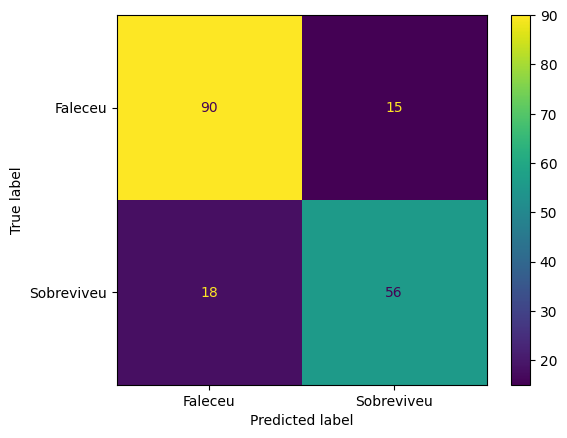

In [31]:


cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Faleceu', 'Sobreviveu'])
disp.plot()
plt.show()


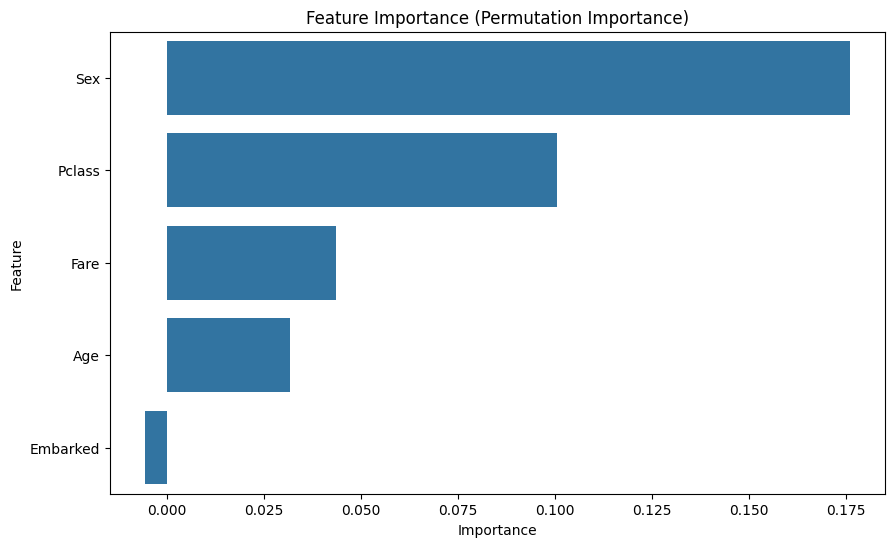

In [32]:


from sklearn.inspection import permutation_importance

# Calcular a importância das features usando permutation importance
result = permutation_importance(pipeline, X_test, y_test, n_repeats=10, random_state=42)

# Criar um DataFrame com os resultados
importance_df = pd.DataFrame({'feature': X.columns, 'importance_mean': result.importances_mean})

# Ordenar as features por importância
importance_df = importance_df.sort_values('importance_mean', ascending=False)

# Plotar a importância das features
plt.figure(figsize=(10, 6))
sns.barplot(x='importance_mean', y='feature', data=importance_df)
plt.title('Feature Importance (Permutation Importance)')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.show()


# SHAP e LIME

--- Executando análise com SHAP ---


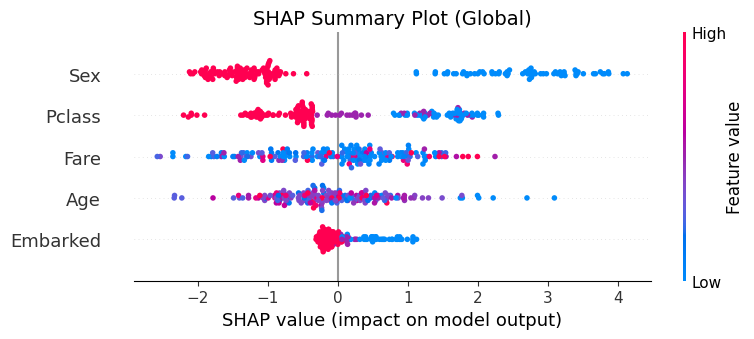

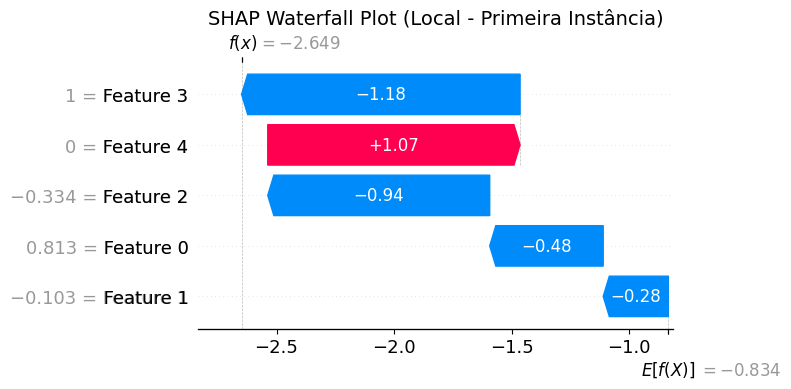


--- Executando análise com LIME ---


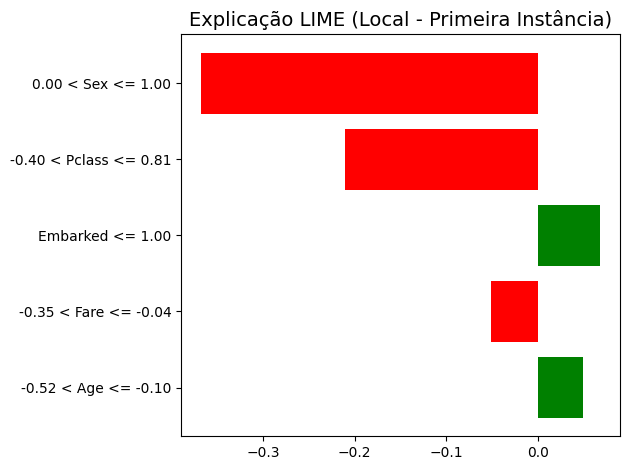

In [34]:
!pip install shap lime

import shap
import lime
import lime.lime_tabular
import matplotlib.pyplot as plt
import numpy as np
from sklearn.impute import SimpleImputer

# 1. Preparação dos dados pós-pipeline para o SHAP
preprocessor = pipeline.named_steps['preprocessor']
classifier = pipeline.named_steps['classifier']

X_train_transformed = preprocessor.transform(X_train)
X_test_transformed = preprocessor.transform(X_test)

# Nomes das features após o ColumnTransformer
feature_names = numerical_columns + categorical_columns_for_transformer

# Como o LIME e o SHAP não lidam bem com NaNs na amostragem interna,
# vamos imputar os NaNs nos arrays transformados apenas para a análise de explicabilidade.
imputer = SimpleImputer(strategy='median')
X_train_clean = imputer.fit_transform(X_train_transformed)
X_test_clean = imputer.transform(X_test_transformed)

# --- ANÁLISE COM SHAP ---
print("--- Executando análise com SHAP ---")
# Usando o TreeExplainer para o HistGradientBoostingClassifier
explainer_shap = shap.TreeExplainer(classifier)
shap_values = explainer_shap(X_test_clean)

# Gráfico de resumo (Summary Plot) global
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test_clean, feature_names=feature_names, show=False)
plt.title("SHAP Summary Plot (Global)", fontsize=14)
plt.tight_layout()
plt.show()

# Gráfico de força (Waterfall Plot) para a primeira instância do teste
plt.figure(figsize=(10, 4))
shap.plots.waterfall(shap_values[0], show=False)
plt.title("SHAP Waterfall Plot (Local - Primeira Instância)", fontsize=14)
plt.tight_layout()
plt.show()

# --- ANÁLISE COM LIME ---
print("\n--- Executando análise com LIME ---")
# Criando o explicador tabular do LIME usando os dados limpos (sem NaNs)
explainer_lime = lime.lime_tabular.LimeTabularExplainer(
    training_data=np.array(X_train_clean),
    feature_names=feature_names,
    class_names=['Faleceu', 'Sobreviveu'],
    mode='classification'
)

# Explicando a primeira instância do conjunto de testes
exp = explainer_lime.explain_instance(
    data_row=X_test_clean[0],
    predict_fn=classifier.predict_proba,
    num_features=len(feature_names)
)

# Mostrando a visualização local do LIME no notebook
fig = exp.as_pyplot_figure()
plt.title("Explicação LIME (Local - Primeira Instância)", fontsize=14)
plt.tight_layout()
plt.show()

### Explicação dos Resultados (SHAP e LIME)

#### 1. SHAP (SHapley Additive exPlanations)
O SHAP nos ajuda a entender o comportamento global do modelo e a tomada de decisão para indivíduos específicos:

* **SHAP Summary Plot (Global):**
  * Este gráfico resume as variáveis mais importantes do modelo de cima para baixo. No caso do Titanic, **Sex** (Gênero) costuma ter o maior impacto. Valores associados ao sexo feminino aumentam as chances de sobrevivência (pontos azuis/vermelhos empurrando a previsão para valores positivos), enquanto o sexo masculino reduz essa probabilidade.
  * **Pclass** (Classe social) também tem forte influência. Classes mais baixas (como a 3ª classe) reduzem significativamente a chance de sobrevivência de um indivíduo.
  
* **SHAP Waterfall Plot (Local):**
  * Explica como o modelo tomou a decisão para a primeira pessoa do conjunto de teste.
  * Começamos a partir do valor base (a média histórica de sobrevivência $E[f(X)]$) e vemos como cada característica (idade, classe, tarifa) contribuiu com forças positivas (geralmente em vermelho/rosa) ou negativas (em azul) para chegar ao valor de previsão final do modelo.

---

#### 2. LIME (Local Interpretable Model-agnostic Explanations)
Enquanto o SHAP tem uma visão global-local integrada, o LIME foca estritamente em aproximar o comportamento do modelo de forma linear e compreensível ao redor de **uma única previsão individual** (nesse caso, o primeiro passageiro do teste):

* **Gráfico LIME (Local):**
  * A barra esquerda exibe a probabilidade atribuída pelo modelo para a classe (`Faleceu` vs. `Sobreviveu`).
  * O gráfico central mostra quais regras e valores de atributos do passageiro mais apoiaram a decisão do modelo ou foram contra ela.
  * Por exemplo, se o passageiro em análise for do sexo masculino (`Sex > 0.5`), isso aparece como uma forte barra de influência contra a sobrevivência dele, justificando a decisão local do classificador.